# 01 – Exploratory data analysis: Zhang et al. (2020) EIS dataset

Goal of this notebook (Day 1, Block 4):
1. Load a raw EIS file and understand its columns.
2. Count cells, temperatures, cycles per cell and frequencies per spectrum.
3. Plot how the impedance spectrum (Nyquist plot) changes as a cell ages.
4. Plot capacity fade for every cell.
5. Check that the preprocessed tutorial CSV agrees with the raw files.

Data: Zhang et al., *Nat. Commun.* 11:1706 (2020), Zenodo [10.5281/zenodo.3633835](https://zenodo.org/records/3633835), CC BY 4.0.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
FIG = Path("../results/figures")
FIG.mkdir(parents=True, exist_ok=True)

# The zips extract into a nested folder ("EIS data/EIS data"); find the folder that actually holds the files.
EIS_DIR = next(p.parent for p in RAW.rglob("EIS_state_V_25C01.txt") if "__MACOSX" not in p.parts)
CAP_DIR = next(p.parent for p in RAW.rglob("Data_Capacity_25C01.txt") if "__MACOSX" not in p.parts)
print(EIS_DIR, CAP_DIR, sep="\n")

..\data\raw\EIS data\EIS data
..\data\raw\Capacity data\Capacity data


## 1. One raw EIS file

Each file holds all spectra of one cell, measured at one state of the charge/discharge cycle.
The file name encodes the state (I–IX), the temperature and the cell: `EIS_state_V_25C01.txt` = state V, 25 °C, cell 01.

**File quirk:** the 25 °C files start with a header line, but the 35 °C and 45 °C files have **no header**
(the first line is already data). The loader detects this and always assigns the same column names.

In [2]:
EIS_COLS = ["time/s", "cycle number", "freq/Hz", "Re(Z)/Ohm", "-Im(Z)/Ohm", "|Z|/Ohm", "Phase(Z)/deg"]

def read_eis(path):
    first = Path(path).read_text().split("\n", 1)[0].split("\t")[0].strip()
    has_header = not first.replace(".", "", 1).replace("-", "", 1).isdigit()
    df = pd.read_csv(path, sep="\t", header=None, skiprows=1 if has_header else 0, usecols=range(7))
    df.columns = EIS_COLS
    return df

eis = read_eis(EIS_DIR / "EIS_state_V_25C01.txt")
print(eis.columns.tolist())
eis.head()

['time/s', 'cycle number', 'freq/Hz', 'Re(Z)/Ohm', '-Im(Z)/Ohm', '|Z|/Ohm', 'Phase(Z)/deg']


,time/s,cycle number,freq/Hz,Re(Z)/Ohm,-Im(Z)/Ohm,|Z|/Ohm,Phase(Z)/deg
0,12836.72676,1.0,20004.4530,0.38470,-0.03513,0.38630,5.21784
1,12836.86976,1.0,15829.1260,0.39156,-0.01700,0.39193,2.48562
2,12837.01176,1.0,12516.7030,0.39684,0.00009,0.39684,-0.01302
3,12837.15376,1.0,9909.4424,0.40341,0.01405,0.40365,-1.99482
4,12837.31776,1.0,7835.4800,0.40963,0.02612,0.41046,-3.64787


In [3]:
freqs = eis.groupby("cycle number")["freq/Hz"].apply(np.array)
n_freq = freqs.apply(len).unique()
print("frequencies per spectrum:", n_freq)
print("highest / lowest frequency [Hz]:", eis["freq/Hz"].max(), "/", eis["freq/Hz"].min())
print("spectra (cycles) in this file:", eis["cycle number"].nunique())

frequencies per spectrum: [60]
highest / lowest frequency [Hz]: 20004.453 / 0.01999
spectra (cycles) in this file: 261


**Note on the sign:** the column is labelled `-Im(Z)` but is *negative* at the highest frequencies.
That is the inductive part of the spectrum (cables and cell geometry): the curve dips below the real axis on the left of the Nyquist plot.

In [4]:
eis[["freq/Hz", "Re(Z)/Ohm", "-Im(Z)/Ohm"]].head(6)

,freq/Hz,Re(Z)/Ohm,-Im(Z)/Ohm
0,20004.4530,0.38470,-0.03513
1,15829.1260,0.39156,-0.01700
2,12516.7030,0.39684,0.00009
3,9909.4424,0.40341,0.01405
4,7835.4800,0.40963,0.02612
5,6217.2461,0.41925,0.03503


## 2. Inventory: states, temperatures, cells

In [5]:
pat = re.compile(r"EIS_state_(?P<state>[IVX]+)_(?P<temp>\d+)C(?P<cell>\d+)\.txt")
rows = []
for p in sorted(EIS_DIR.glob("EIS_state_*.txt")):
    m = pat.fullmatch(p.name)
    if m:
        rows.append({**m.groupdict(), "file": p.name})
inv = pd.DataFrame(rows)
inv["cell_id"] = inv["temp"] + "C" + inv["cell"]
print("EIS files:", len(inv))
pd.crosstab(inv["cell_id"], inv["state"])

EIS files: 88


state,I,II,III,IV,IX,V,VI,VII,VIII
cell_id,,,,,,,,,
25C01,1,1,1,1,1,1,1,0,0
25C02,1,1,1,1,1,1,1,0,0
25C03,1,1,1,1,1,1,1,0,0
25C04,1,1,1,1,1,1,0,1,1
25C05,1,1,1,1,1,1,1,0,0
25C06,1,1,1,1,1,1,1,1,1
25C07,1,1,1,1,1,1,1,1,1
25C08,1,1,1,1,1,1,1,1,1
25C42,0,0,0,0,0,0,1,0,0


States V and I–IV are available for all 12 cells; states VI–VIII only for some 25 °C cells.
`25C42` appears only once (state VI) and is not one of the 12 cells described in the paper, so we ignore it.

We use **state V** (fully charged, rested 15 min), the state used in the paper and in the tutorial CSV.

In [6]:
CELLS = [f"25C0{i}" for i in range(1, 9)] + ["35C01", "35C02", "45C01", "45C02"]

summary = []
for c in CELLS:
    df = read_eis(EIS_DIR / f"EIS_state_V_{c}.txt")
    summary.append({
        "cell": c,
        "temp_C": int(c[:2]),
        "n_spectra": df["cycle number"].nunique(),
        "n_freq": df.groupby("cycle number").size().unique().tolist(),
    })
summary = pd.DataFrame(summary)
summary

,cell,temp_C,n_spectra,n_freq
0,25C01,25,261,[60]
1,25C02,25,250,[60]
2,25C03,25,229,[60]
3,25C04,25,81,[60]
4,25C05,25,275,[60]
5,25C06,25,212,[60]
6,25C07,25,140,[60]
7,25C08,25,86,[60]
8,35C01,35,327,[60]
9,35C02,35,318,[60]


In [7]:
print("cells:", len(summary), "| per temperature:", summary.groupby("temp_C").size().to_dict())
print("total state-V spectra:", summary["n_spectra"].sum())

cells: 12 | per temperature: {25: 8, 35: 2, 45: 2}
total state-V spectra: 2788


## 3. Capacity data

**File quirks:**
- The header line uses spaces instead of a tab between `cycle number` and `ox/red`, so we skip it and set the column names ourselves.
- Files have two layouts: 4 columns (`time, cycle, ox/red, capacity`) or 6 columns (with `Ewe/V` and `I/mA` before capacity).
  In both, capacity is the **last** column.

Each file is a time series. `Capacity/mA.h` accumulates within each half-cycle; `ox/red` marks the half-cycle.
The maximum of each half-cycle is the capacity of that charge or discharge.
Comparing with the tutorial CSV (Section 5) shows that `ox/red == 0` is the discharge capacity the tutorial uses as `Q`.

In [8]:
def read_capacity(cell):
    df = pd.read_csv(CAP_DIR / f"Data_Capacity_{cell}.txt", sep="\t", skiprows=1, header=None)
    df = df.dropna(axis=1, how="all")               # trailing tab -> empty last column
    df = pd.DataFrame({"cycle": df.iloc[:, 1], "ox_red": df.iloc[:, 2], "capacity_mAh": df.iloc[:, -1]})
    per_cycle = df.groupby(["cycle", "ox_red"])["capacity_mAh"].max().unstack()
    # ox_red == 0 -> discharge (verified in Section 5); the last cycle can lack a discharge -> drop NaN
    return per_cycle[0].dropna().rename("discharge_mAh")

cap = {c: read_capacity(c) for c in CELLS}
pd.DataFrame({c: [s.index.size, s.iloc[0], s.iloc[-1]] for c, s in cap.items()},
             index=["n_cycles", "first_mAh", "last_mAh"]).T.round(2)

,n_cycles,first_mAh,last_mAh
25C01,350.0,37.20,8.90
25C02,181.0,35.06,24.88
25C03,202.0,36.77,27.49
25C04,35.0,35.53,30.79
25C05,328.0,37.21,0.02
25C06,213.0,35.99,19.22
25C07,148.0,35.68,15.35
25C08,37.0,33.94,25.83
35C01,327.0,40.11,14.44
35C02,318.0,40.47,27.12


**EIS spectra vs capacity cycles do not always match.** Some cells have more spectra than capacity
values, others fewer. A spectrum can only be labelled if a capacity exists for cycle *n − 1*,
so the number of usable (labelled) spectra per cell is limited by both files:

In [9]:
usable = summary.set_index("cell")[["temp_C", "n_spectra"]].copy()
usable["n_capacity_cycles"] = [len(cap[c]) for c in usable.index]
usable["n_labelled"] = [
    int(np.isin(read_eis(EIS_DIR / f"EIS_state_V_{c}.txt")["cycle number"].unique() - 1, cap[c].index).sum())
    for c in usable.index
]
usable["final_SoH"] = [round(cap[c].iloc[-1] / cap[c].iloc[0], 3) for c in usable.index]
usable

,temp_C,n_spectra,n_capacity_cycles,n_labelled,final_SoH
cell,,,,,
25C01,25,261,350,261,0.239
25C02,25,250,181,181,0.710
25C03,25,229,202,202,0.748
25C04,25,81,35,35,0.866
25C05,25,275,328,275,0.001
25C06,25,212,213,212,0.534
25C07,25,140,148,140,0.430
25C08,25,86,37,37,0.761
35C01,35,327,327,327,0.360


## 4. Figures

### 4a. Nyquist plot: how the spectrum changes with aging (cell 25C01, state V)

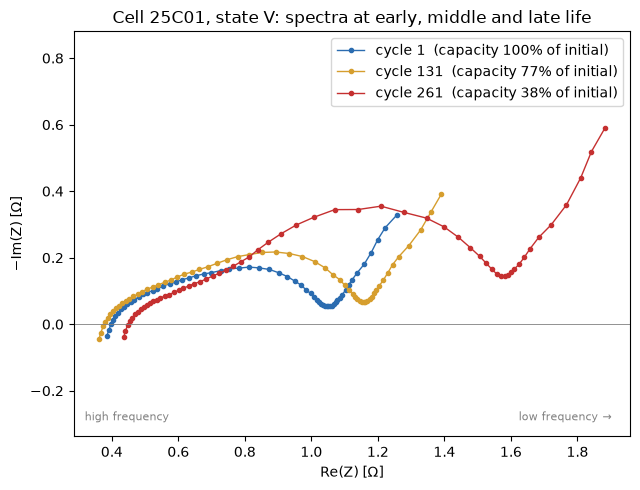

In [10]:
cell = "25C01"
df = read_eis(EIS_DIR / f"EIS_state_V_{cell}.txt")
cycles = np.sort(df["cycle number"].unique())
picks = [cycles[0], cycles[len(cycles) // 2], cycles[-1]]
cap_c = cap[cell]

fig, ax = plt.subplots(figsize=(6.5, 5))
for cyc, color in zip(picks, ["#2b6cb0", "#d69e2e", "#c53030"]):
    s = df[df["cycle number"] == cyc]
    q = cap_c.loc[cyc - 1] / cap_c.iloc[0]          # EIS cycle n <-> capacity cycle n-1 (Section 5)
    ax.plot(s["Re(Z)/Ohm"], s["-Im(Z)/Ohm"], "o-", ms=3, lw=1, color=color,
            label=f"cycle {int(cyc)}  (capacity {q:.0%} of initial)")
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Re(Z) [Ω]")
ax.set_ylabel("−Im(Z) [Ω]")
ax.set_title(f"Cell {cell}, state V: spectra at early, middle and late life")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.annotate("high frequency", xy=(0.02, 0.04), xycoords="axes fraction", fontsize=8, color="grey")
ax.annotate("low frequency →", xy=(0.80, 0.04), xycoords="axes fraction", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(FIG / "eda_nyquist_aging.png", dpi=150)
plt.show()

**What to look for** (write your own observations in `NOTES.md`):
- Does the high-frequency intercept (≈ ohmic resistance R0) move right with age?
- Does the mid-frequency semicircle (charge transfer) grow?
- What happens to the low-frequency tail?

### 4b. Capacity fade of all 12 cells

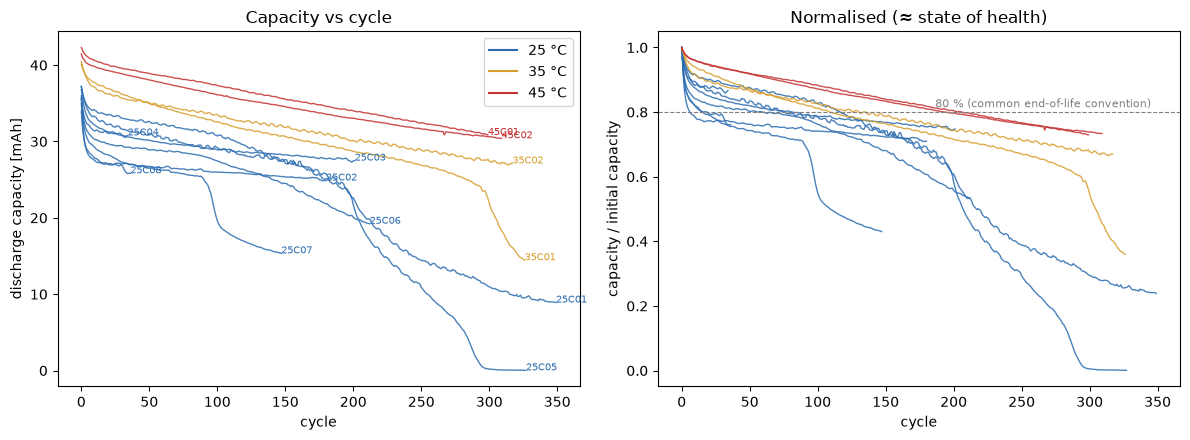

In [11]:
colors = {25: "#2b6cb0", 35: "#d69e2e", 45: "#c53030"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for c, s in cap.items():
    t = int(c[:2])
    axes[0].plot(s.index, s.values, lw=1, color=colors[t], alpha=0.85)
    axes[1].plot(s.index, s.values / s.iloc[0], lw=1, color=colors[t], alpha=0.85)
    axes[0].annotate(c, (s.index[-1], s.values[-1]), fontsize=7, color=colors[t])
for t, col in colors.items():
    axes[0].plot([], [], color=col, label=f"{t} °C")
axes[0].set(xlabel="cycle", ylabel="discharge capacity [mAh]", title="Capacity vs cycle")
axes[1].set(xlabel="cycle", ylabel="capacity / initial capacity", title="Normalised (≈ state of health)")
axes[1].axhline(0.8, color="grey", ls="--", lw=0.8)
axes[1].annotate("80 % (common end-of-life convention)", (345, 0.815), fontsize=8, color="grey", ha="right")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "eda_capacity_fade.png", dpi=150)
plt.show()

## 5. Does the tutorial CSV agree with the raw files?

The tutorial CSV (`data_eis_zhang2020.csv`, from the MIT-licensed
[battery-data-commons/mrs-sp22-tutorial](https://github.com/battery-data-commons/mrs-sp22-tutorial))
has one row per spectrum with columns `ZReal_*`, `ZImag_*`, `Z_*`, `ZPhase_*` and capacity `Q`, `q`.
Hypothesis: `seriesIdx` k = cell `25C0k`, state V. We test it on 3 random rows.

In [12]:
tut = pd.read_csv(RAW / "data_eis_zhang2020.csv")
print(tut.shape)
tut.groupby("seriesIdx").agg(n_spectra=("cycle", "size"), last_cycle=("cycle", "max"), min_q=("q", "min")).round(3)

(1343, 244)


,n_spectra,last_cycle,min_q
seriesIdx,,,
1,261,261,0.370
2,181,181,0.709
3,202,202,0.742
4,35,35,0.859
5,275,275,0.184
6,212,212,0.535
7,140,140,0.442
8,37,37,0.760


In [13]:
re_cols = [c for c in tut.columns if c.startswith("ZReal_")]
im_cols = [c for c in tut.columns if c.startswith("ZImag_")]

rng = np.random.default_rng(0)
checks = []
for i in rng.choice(len(tut), size=3, replace=False):
    row = tut.iloc[i]
    cell = f"25C0{int(row.seriesIdx)}"
    raw_s = read_eis(EIS_DIR / f"EIS_state_V_{cell}.txt")
    raw_s = raw_s[raw_s["cycle number"] == row.cycle]
    d_re = np.abs(row[re_cols].to_numpy(float) - raw_s["Re(Z)/Ohm"].to_numpy()).max()
    d_im_same = np.abs(row[im_cols].to_numpy(float) - raw_s["-Im(Z)/Ohm"].to_numpy()).max()
    d_im_flip = np.abs(row[im_cols].to_numpy(float) + raw_s["-Im(Z)/Ohm"].to_numpy()).max()
    q_raw = cap[cell].loc[row.cycle - 1]
    checks.append({"row": i, "cell": cell, "cycle": int(row.cycle),
                   "max|ΔRe|": d_re, "max|ΔIm| (same sign)": d_im_same, "max|ΔIm| (flipped)": d_im_flip,
                   "Q_csv": row.Q, "Q_raw (cycle n-1)": q_raw})
pd.DataFrame(checks)

,row,cell,cycle,max|ΔRe|,max|ΔIm| (same sign),max|ΔIm| (flipped),Q_csv,Q_raw (cycle n-1)
0,854,25C05,176,0.0,0.0,0.71052,25.826867,25.826867
1,686,25C05,8,0.0,0.0,0.63932,33.456646,33.456646
2,1140,25C06,187,0.0,0.0,0.82650,21.223972,21.223972


## 6. Summary

The printed tables above are the source of truth; the key numbers are copied into `NOTES.md`.
- Spectrum format: 60 frequencies, 20 kHz → 0.02 Hz.
- 12 cells: 8 at 25 °C, 2 at 35 °C, 2 at 45 °C; very different lifetimes (see Section 2).
- Label pairing: EIS cycle *n* ↔ discharge capacity of capacity-file cycle *n − 1* (matches the tutorial exactly).
- The tutorial CSV covers the eight 25 °C cells at state V only, truncated to cycles that have a capacity label.
- The tutorial's `ZImag_*` columns equal the raw `-Im(Z)` column (same sign), despite the name.